# Final Project: Agentic AI with RAG for CleanTech Domain

**Student Name:** Joseph Giwa  
**Course:** CSC 583 - Natural Language Processing  
**Assignment:** Final Project - Agentic AI System with Advanced RAG

## Project Overview

This project implements a comprehensive agentic AI system using LangChain framework for question-answering in the CleanTech domain. The system includes:

### Part 1: Core Implementation
- **Retrieval Tool:** Vector database (Chroma) with semantic search
- **Summarizer Tool:** Context-aware response generation
- **Agent Orchestration:** LangChain-based tool selection and execution

### Part 2: Custom Extensions (Built from Scratch)
1. **Web Search Integration:** Real-time information retrieval via Brave Search API
2. **Reasoning Chain Module:** Transparent step-by-step reasoning with explanation
3. **Conversation Memory System:** Context-aware multi-turn conversations

### Part 3: Comprehensive Evaluation
- Retrieval accuracy metrics (Precision, Recall, MRR)
- Response quality metrics (BLEU, ROUGE, Semantic Similarity)
- LLM-as-Judge evaluation
- Analysis on 50-question complex test set

## Setup and Installation

First, we install all required dependencies.

In [1]:
%%capture
# Uninstall all LangChain packages
!pip uninstall -y langchain langchain-core langchain-openai langchain-community

# Install stable versions with AgentExecutor (0.3.x series)
!pip install langchain==0.3.7
!pip install langchain-core==0.3.21
!pip install langchain-openai==0.2.9
!pip install langchain-community==0.3.7

# Reinstall other dependencies
!pip install chromadb==0.4.24
!pip install tiktoken==0.6.0
!pip install sentence-transformers==2.6.1
!pip install rouge-score==0.1.2
!pip install nltk==3.8.1
!pip install requests==2.31.0
!pip install beautifulsoup4==4.12.3
!pip install openpyxl==3.1.2

print("Installation complete")

In [ ]:
import os
os.kill(os.getpid(), 9)

## Import Libraries

In [1]:
# Standard libraries
import os
import sys
import json
import time
import warnings
from typing import List, Dict, Any, Optional, Tuple
from datetime import datetime
import re

# Data manipulation
import pandas as pd
import numpy as np

# LangChain imports
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_community.vectorstores import Chroma
from langchain_core.documents import Document
from langchain_core.tools import Tool
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain.agents import AgentExecutor, create_react_agent
from langchain.agents.output_parsers.openai_tools import OpenAIToolsAgentOutputParser
from langchain.agents.format_scratchpad.openai_tools import format_to_openai_tool_messages

# Evaluation
from sklearn.metrics import precision_score, recall_score
from rouge_score import rouge_scorer
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from sentence_transformers import SentenceTransformer, util

# Web
import requests
from bs4 import BeautifulSoup

warnings.filterwarnings('ignore')

import nltk
nltk.download('punkt', quiet=True)

print("All libraries imported successfully")

All libraries imported successfully


## Configuration and API Keys

In [2]:
# API Keys
OPENAI_API_KEY = "REDACTED"
BRAVE_API_KEY = "REDACTED"

# Set environment variable
os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY

# Configuration parameters
CONFIG = {
    'embedding_model': 'text-embedding-3-small',
    'llm_model': 'gpt-4o-mini',
    'llm_eval_model': 'gpt-4o',
    'temperature': 0.0,
    'chunk_size': 1000,
    'chunk_overlap': 200,
    'top_k_retrieval': 5,
    'vector_db_path': './chroma_database_v2',
}

print("Configuration loaded successfully")
print(f"  - LLM Model: {CONFIG['llm_model']}")
print(f"  - Embedding Model: {CONFIG['embedding_model']}")
print(f"  - Vector DB Path: {CONFIG['vector_db_path']}")

Configuration loaded successfully
  - LLM Model: gpt-4o-mini
  - Embedding Model: text-embedding-3-small
  - Vector DB Path: ./chroma_database_v2


## Data Loading and Preprocessing

We'll load the CleanTech media dataset and prepare it for vector database ingestion.

In [8]:
# Mount Google Drive to access the dataset
from google.colab import drive
drive.mount('/content/drive')

# Path to the dataset
DATASET_PATH = '/content/drive/MyDrive/cleantech_media_dataset_v3_2024-10-28.csv'

print("Google Drive mounted successfully")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted successfully


In [12]:
def load_cleantech_dataset(file_path: str) -> pd.DataFrame:
    """
    Load the CleanTech media dataset from CSV.

    Args:
        file_path: Path to the CSV file

    Returns:
        DataFrame containing the dataset
    """
    print(f"Loading dataset from: {file_path}")

    df = pd.read_csv(file_path, encoding='utf-8')

    print(f"Dataset loaded: {len(df)} articles")
    print(f"  - Columns: {list(df.columns)}")
    print(f"  - Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

    return df

# Load the dataset
cleantech_df = load_cleantech_dataset(DATASET_PATH)
cleantech_df = cleantech_df.rename(columns={'Unnamed: 0': 'id'})

print("Column renamed successfully")
print(f"Columns now: {cleantech_df.columns.tolist()}")
print(f"\nFirst few IDs: {cleantech_df['id'].head().tolist()}")

# # Display first few rows
# print("\nSample data:")
# cleantech_df.head(3)

Loading dataset from: /content/drive/MyDrive/cleantech_media_dataset_v3_2024-10-28.csv
Dataset loaded: 20111 articles
  - Columns: ['Unnamed: 0', 'title', 'date', 'author', 'content', 'domain', 'url']
  - Memory usage: 200.55 MB
Column renamed successfully
Columns now: ['id', 'title', 'date', 'author', 'content', 'domain', 'url']

First few IDs: [93320, 93321, 98159, 98158, 31128]


In [13]:
def preprocess_documents(df: pd.DataFrame) -> List[Document]:
    """
    Preprocess the dataset and convert to LangChain Document format.

    Args:
        df: DataFrame containing article data

    Returns:
        List of LangChain Document objects
    """
    documents = []
    print("Preprocessing documents...")

    for idx, row in df.iterrows():
        title = str(row.get('title', '')).strip()
        content = str(row.get('content', '')).strip()

        if not title and not content:
            continue

        page_content = f"Title: {title}\n\nContent: {content}"

        metadata = {
            'article_id': str(row.get('id', idx)),
            'url': str(row.get('url', '')),
            'published_date': str(row.get('published', '')),
            'title': title,
        }

        doc = Document(
            page_content=page_content,
            metadata=metadata
        )
        documents.append(doc)

        if (idx + 1) % 1000 == 0:
            print(f"  Processed {idx + 1}/{len(df)} documents")

    print(f"\nPreprocessed {len(documents)} documents")
    return documents

# Preprocess documents
documents = preprocess_documents(cleantech_df)

# Display sample document
print("\nSample document:")
print(f"Content preview: {documents[0].page_content[:300]}...")
print(f"Metadata: {documents[0].metadata}")

Preprocessing documents...
  Processed 1000/20111 documents
  Processed 2000/20111 documents
  Processed 3000/20111 documents
  Processed 4000/20111 documents
  Processed 5000/20111 documents
  Processed 6000/20111 documents
  Processed 7000/20111 documents
  Processed 8000/20111 documents
  Processed 9000/20111 documents
  Processed 10000/20111 documents
  Processed 11000/20111 documents
  Processed 12000/20111 documents
  Processed 13000/20111 documents
  Processed 14000/20111 documents
  Processed 15000/20111 documents
  Processed 16000/20111 documents
  Processed 17000/20111 documents
  Processed 18000/20111 documents
  Processed 19000/20111 documents
  Processed 20000/20111 documents

Preprocessed 20111 documents

Sample document:
Content preview: Title: XPeng Delivered ~100,000 Vehicles In 2021

Content: ['Chinese automotive startup XPeng has shown one of the most dramatic auto production ramp-ups in history, and the good news is it only produces 100% smart electric vehicles ( EV

# Part 1: Core System Implementation

## 1.1 Vector Database Creation

We create a Chroma vector database with OpenAI embeddings for semantic search.

In [14]:
# Change to completely new database path
CONFIG['vector_db_path'] = './chroma_database_v2'

print(f"New database path: {CONFIG['vector_db_path']}")

New database path: ./chroma_database_v2


In [15]:
def create_vector_database_fast(documents: List[Document], persist_directory: str) -> Chroma:
    """
    Fast vector database creation with rate limit handling.
    """
    print(f"Creating vector database")
    print(f"Total documents: {len(documents):,}")

    embeddings = OpenAIEmbeddings(
        model=CONFIG['embedding_model'],
        chunk_size=100,
        max_retries=3
    )

    batch_size = 100

    print(f"\nUsing batch size: {batch_size}")
    print(f"Estimated time: {(len(documents) / batch_size) * 0.5:.1f} minutes")
    print(f"Estimated cost: ${len(documents) * 0.0001:.2f}\n")

    start_time = time.time()

    # Create with first batch
    print("Creating database with first batch...")
    vectorstore = Chroma.from_documents(
        documents=documents[:batch_size],
        embedding=embeddings,
        persist_directory=persist_directory,
        collection_name="cleantech_articles"
    )

    # Process remaining in batches
    total_batches = (len(documents) - 1) // batch_size + 1
    print(f"Batch 1/{total_batches} complete")

    for i in range(batch_size, len(documents), batch_size):
        batch = documents[i:i+batch_size]

        try:
            vectorstore.add_documents(batch)

            batch_num = i // batch_size + 1
            progress = (i / len(documents)) * 100
            elapsed = time.time() - start_time
            eta = (elapsed / i) * (len(documents) - i)

            print(f"Batch {batch_num}/{total_batches} ({progress:.1f}% | ETA: {eta/60:.1f}m)")

            time.sleep(2)

        except Exception as e:
            print(f"Error on batch {i//batch_size + 1}: {e}")
            print("Waiting 30 seconds before retry...")
            time.sleep(30)
            vectorstore.add_documents(batch)
            print("Retry successful")

    total_time = time.time() - start_time
    print(f"\nComplete in {total_time/60:.1f} minutes")
    print(f"  - Documents: {len(documents):,}")
    print(f"  - Location: {persist_directory}")

    return vectorstore

# Create or load vector database
if os.path.exists(CONFIG['vector_db_path']):
    print("Loading existing vector database...")
    embeddings = OpenAIEmbeddings(
        model=CONFIG['embedding_model']
    )
    vectorstore = Chroma(
        persist_directory=CONFIG['vector_db_path'],
        embedding_function=embeddings,
        collection_name="cleantech_articles"
    )
    print("Vector database loaded")
else:
    print("No existing database found. Creating new one...")
    vectorstore = create_vector_database_fast(documents, CONFIG['vector_db_path'])

# Test retrieval
test_query = "What are the latest developments in solar energy?"
test_results = vectorstore.similarity_search(test_query, k=3)
print(f"\nTest retrieval for: '{test_query}'")
print(f"Retrieved {len(test_results)} documents")
print(f"First result: {test_results[0].metadata['title'][:100]}...")

No existing database found. Creating new one...
Creating vector database
Total documents: 20,111

Using batch size: 100
Estimated time: 100.6 minutes
Estimated cost: $2.01

Creating database with first batch...


ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientStartEvent: capture() takes 1 positional argument but 3 were given
ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientCreateCollectionEvent: capture() takes 1 positional argument but 3 were given


Batch 1/202 complete
Batch 2/202 (0.5% | ETA: 35.0m)
Batch 3/202 (1.0% | ETA: 25.6m)
Batch 4/202 (1.5% | ETA: 22.0m)
Batch 5/202 (2.0% | ETA: 20.4m)
Batch 6/202 (2.5% | ETA: 19.9m)
Batch 7/202 (3.0% | ETA: 18.8m)
Batch 8/202 (3.5% | ETA: 18.6m)
Batch 9/202 (4.0% | ETA: 18.2m)
Batch 10/202 (4.5% | ETA: 18.0m)
Batch 11/202 (5.0% | ETA: 17.7m)
Batch 12/202 (5.5% | ETA: 17.4m)
Batch 13/202 (6.0% | ETA: 17.2m)
Batch 14/202 (6.5% | ETA: 17.0m)
Batch 15/202 (7.0% | ETA: 16.7m)
Batch 16/202 (7.5% | ETA: 16.6m)
Batch 17/202 (8.0% | ETA: 16.5m)
Batch 18/202 (8.5% | ETA: 16.3m)
Batch 19/202 (9.0% | ETA: 16.1m)
Batch 20/202 (9.4% | ETA: 16.0m)
Batch 21/202 (9.9% | ETA: 15.8m)
Batch 22/202 (10.4% | ETA: 15.6m)
Batch 23/202 (10.9% | ETA: 15.4m)
Batch 24/202 (11.4% | ETA: 15.2m)
Batch 25/202 (11.9% | ETA: 15.2m)
Batch 26/202 (12.4% | ETA: 15.1m)
Batch 27/202 (12.9% | ETA: 14.9m)
Batch 28/202 (13.4% | ETA: 14.8m)
Batch 29/202 (13.9% | ETA: 14.7m)
Batch 30/202 (14.4% | ETA: 14.6m)
Batch 31/202 (14.9% |

ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event CollectionQueryEvent: capture() takes 1 positional argument but 3 were given



Complete in 20.1 minutes
  - Documents: 20,111
  - Location: ./chroma_database_v2

Test retrieval for: 'What are the latest developments in solar energy?'
Retrieved 3 documents
First result: Solar Cell Production ( Solar Energy) Articles...


## 1.2 Core Tools Implementation (WITH FIX)

We implement the two required tools: Retriever and Summarizer.

**FIX:** Added article ID tracking to RetrieverTool to properly calculate retrieval metrics.

In [16]:
class RetrieverTool:
    """
    Retriever tool for semantic search in the vector database.

    FIXED: Now tracks retrieved article IDs for proper evaluation metrics.
    """
    def __init__(self, vectorstore: Chroma, top_k: int = 5):
        self.vectorstore = vectorstore
        self.top_k = top_k
        self.last_retrieved_ids = []  # Track retrieved IDs
        self.last_retrieved_docs = []  # Track full documents

    def retrieve(self, query: str) -> str:
        """
        Retrieve relevant documents for a query.

        Args:
            query: Search query string

        Returns:
            Formatted string containing retrieved documents
        """
        # Perform similarity search
        results = self.vectorstore.similarity_search(
            query,
            k=self.top_k
        )

        # Store retrieved IDs and documents for evaluation
        self.last_retrieved_ids = [
            doc.metadata.get('article_id', 'N/A')
            for doc in results
        ]
        self.last_retrieved_docs = results

        # Format results
        formatted_results = []
        for i, doc in enumerate(results, 1):
            formatted_results.append(
                f"Document {i}:\n"
                f"Article ID: {doc.metadata.get('article_id', 'N/A')}\n"
                f"Title: {doc.metadata.get('title', 'N/A')}\n"
                f"Content: {doc.page_content[:500]}...\n"
                f"URL: {doc.metadata.get('url', 'N/A')}\n"
            )

        return "\n---\n".join(formatted_results)

# Initialize retriever tool
retriever_tool = RetrieverTool(vectorstore, top_k=CONFIG['top_k_retrieval'])
print("Retriever tool initialized with ID tracking")

Retriever tool initialized with ID tracking


In [17]:
class SummarizerTool:
    """
    Summarizer tool for generating context-aware responses.
    """
    def __init__(self, llm: ChatOpenAI):
        self.llm = llm

    def summarize(self, query: str, context: str) -> str:
        """
        Generate a summary/answer based on query and context.

        Args:
            query: User's question
            context: Retrieved context from documents

        Returns:
            Generated answer/summary
        """
        prompt = f"""Based on the following context from CleanTech articles, answer the question.

Context:
{context}

Question: {query}

Instructions:
1. Answer the question directly and concisely
2. Use only information from the provided context
3. If the context doesn't contain enough information, state that clearly
4. Cite specific details from the context when possible
5. Maintain factual accuracy

Answer:"""

        response = self.llm.invoke(prompt)
        return response.content

# Initialize LLM for summarizer
llm = ChatOpenAI(
    model=CONFIG['llm_model'],
    temperature=CONFIG['temperature'],
    openai_api_key=OPENAI_API_KEY
)

# Initialize summarizer tool
summarizer_tool = SummarizerTool(llm)
print("Summarizer tool initialized")

Summarizer tool initialized


## 1.3 Agent Orchestration

We create a LangChain agent that orchestrates the tools to answer questions.

In [18]:
def create_base_agent(vectorstore: Chroma, llm: ChatOpenAI) -> AgentExecutor:
    """
    Create a LangChain agent with retriever and summarizer tools.
    """
    # Initialize tools
    retriever = RetrieverTool(vectorstore)
    summarizer = SummarizerTool(llm)

    # Define tools for agent
    tools = [
        Tool(
            name="retrieve_documents",
            func=retriever.retrieve,
            description="""Use this tool to retrieve relevant CleanTech articles from the database.
            Input should be a search query string.
            Returns: Top relevant documents with their content and metadata."""
        ),
        Tool(
            name="summarize_and_answer",
            func=lambda query: summarizer.summarize(
                query,
                retriever.retrieve(query)
            ),
            description="""Use this tool to generate an answer to a question based on retrieved documents.
            Input should be the user's question.
            Returns: A comprehensive answer based on relevant CleanTech articles."""
        )
    ]

    # Create ReAct prompt template
    prompt = ChatPromptTemplate.from_messages([
        ("system", """You are an expert assistant specializing in CleanTech and renewable energy.
        Your role is to answer questions using information from a database of CleanTech articles.

        You have access to the following tools:

        {tools}

        Use the following format:

        Question: the input question you must answer
        Thought: you should always think about what to do
        Action: the action to take, should be one of [{tool_names}]
        Action Input: the input to the action
        Observation: the result of the action
        ... (this Thought/Action/Action Input/Observation can repeat N times)
        Thought: I now know the final answer
        Final Answer: the final answer to the original input question

        Begin!

        Question: {input}
        Thought: {agent_scratchpad}"""),
    ])

    # Create agent
    agent = create_react_agent(llm, tools, prompt)

    # Create agent executor
    agent_executor = AgentExecutor(
        agent=agent,
        tools=tools,
        verbose=True,
        handle_parsing_errors=True,
        max_iterations=5
    )

    return agent_executor

# Create base agent
base_agent = create_base_agent(vectorstore, llm)
print("Base agent created successfully")

Base agent created successfully


## 1.4 Test Base System

In [19]:
# Load test queries
eval_df = pd.read_csv(
    '/content/drive/MyDrive/cleantech_rag_evaluation_data_2024-09-20.csv',
    delimiter=';'
)

print(f"Loaded {len(eval_df)} test queries")
print(f"Columns: {list(eval_df.columns)}")
print("\nSample queries:")
eval_df[['question_id', 'question']].head()

Loaded 23 test queries
Columns: ['example_id', 'question_id', 'question', 'relevant_text', 'answer', 'article_url']

Sample queries:


,question_id,question
0,1,What is the innovation behind Leclanché's new ...
1,2,What is the EU’s Green Deal Industrial Plan?
2,2,What is the EU’s Green Deal Industrial Plan?
3,3,What are the four focus areas of the EU's Gree...
4,4,When did the cooperation between GM and Honda ...


In [20]:
# Test with a few sample queries
test_queries = eval_df['question'].head(3).tolist()

print("Testing base system with sample queries:\n")

for i, query in enumerate(test_queries, 1):
    print(f"\n{'='*80}")
    print(f"Query {i}: {query}")
    print(f"{'='*80}\n")

    try:
        result = base_agent.invoke({"input": query})
        print(f"\nAnswer: {result['output']}")
    except Exception as e:
        print(f"Error: {str(e)}")

    print(f"\n{'='*80}")
    time.sleep(2)

Testing base system with sample queries:


Query 1: What is the innovation behind Leclanché's new method to produce lithium-ion batteries?



> Entering new AgentExecutor chain...
Action: retrieve_documents  
Action Input: "Leclanché new method lithium-ion batteries innovation"  Document 1:
Article ID: 43308
Title: Leclanché’ s new disruptive battery boosts energy density
Content: Title: Leclanché’ s new disruptive battery boosts energy density

Content: ['Energy storage company Leclanché ( SW.LECN) has designed a new battery cell that uses less cobalt and boosts energy density by 20%. The company says it is also produced in an environmentally friendly way, making it more recyclable or easy to dispose of at end-of-life.', 'Leclanché said it has developed an environmentally friendly way to produce lithium-ion ( Li-ion) batteries. It has replaced highly toxic organic solven...
URL: https://sgvoice.energyvoice.com/strategy/technology/23971/leclanches-new-disruptive-battery-boosts-energy-d

# Part 2: Custom Extensions - Built from Scratch

## 2.1 Extension 1: Web Search Integration

In [21]:
class WebSearchTool:
    """
    Custom web search tool using Brave Search API.
    """
    def __init__(self, api_key: str, max_results: int = 5):
        self.api_key = api_key
        self.max_results = max_results
        self.base_url = "https://api.search.brave.com/res/v1/web/search"

    def search(self, query: str) -> str:
        """
        Perform a web search and return formatted results.
        """
        try:
            headers = {
                "Accept": "application/json",
                "X-Subscription-Token": self.api_key
            }

            params = {
                "q": query,
                "count": self.max_results,
                "text_decorations": False,
                "search_lang": "en"
            }

            response = requests.get(
                self.base_url,
                headers=headers,
                params=params,
                timeout=10
            )

            if response.status_code != 200:
                return f"Web search failed with status code: {response.status_code}"

            data = response.json()

            if 'web' not in data or 'results' not in data['web']:
                return "No web search results found."

            results = data['web']['results']

            if not results:
                return "No web search results found."

            formatted_results = []
            for i, result in enumerate(results[:self.max_results], 1):
                formatted_results.append(
                    f"Result {i}:\n"
                    f"Title: {result.get('title', 'N/A')}\n"
                    f"Description: {result.get('description', 'N/A')}\n"
                    f"URL: {result.get('url', 'N/A')}\n"
                )

            return "\n---\n".join(formatted_results)

        except requests.exceptions.Timeout:
            return "Web search request timed out."
        except requests.exceptions.RequestException as e:
            return f"Web search error: {str(e)}"
        except Exception as e:
            return f"Unexpected error during web search: {str(e)}"

# Initialize web search tool
web_search_tool = WebSearchTool(api_key=BRAVE_API_KEY, max_results=5)

# Test the web search tool
test_result = web_search_tool.search("latest developments in solar energy 2024")
print("Web Search Tool initialized and tested")
print(f"\nTest search result preview:\n{test_result[:500]}...")

Web Search Tool initialized and tested

Test search result preview:
Result 1:
Title: 7 New Solar Panel Technology Trends for 2025
Description: As of early 2024, startups and major manufacturers around the world, including Oxford PV, Saule Technologies, and Tandem PV, are racing to commercialize these next-gen solar cells, with pilot lines already producing early-stage modules.
URL: https://www.greenlancer.com/post/solar-panel-technology-trends

---
Result 2:
Title: These breakthroughs are making solar panels more efficient | World Economic Forum
Description: Thr...


## 2.2 Extension 2: Reasoning Chain Module

In [22]:
class ReasoningChainTool:
    """
    Custom reasoning chain tool for transparent step-by-step reasoning.
    """
    def __init__(self, llm: ChatOpenAI, vectorstore: Chroma):
        self.llm = llm
        self.vectorstore = vectorstore

    def reason(self, query: str, context: Optional[str] = None) -> str:
        """
        Generate a reasoning chain for answering the query.
        """
        # Retrieve relevant information
        retrieved_docs = self.vectorstore.similarity_search(query, k=5)

        # Format retrieved context
        retrieved_context = "\n\n".join([
            f"Source {i+1} (ID: {doc.metadata.get('article_id', 'N/A')}): {doc.page_content[:500]}..."
            for i, doc in enumerate(retrieved_docs)
        ])

        # Combine contexts
        full_context = retrieved_context
        if context:
            full_context += f"\n\nAdditional Context:\n{context}"

        # Generate reasoning chain
        reasoning_prompt = f"""You are an expert at breaking down complex questions into clear reasoning steps.

Question: {query}

Available Information:
{full_context}

Please provide a structured reasoning chain to answer this question:

1. QUESTION ANALYSIS: What is being asked and what information is needed?
2. EVIDENCE GATHERING: What relevant facts are available in the sources?
3. REASONING STEPS: What logical steps lead to the answer?
4. CONCLUSION: What is the final answer based on the reasoning?
5. CONFIDENCE: How confident are we in this answer? What are the limitations?

Provide a clear, step-by-step explanation."""

        response = self.llm.invoke(reasoning_prompt)

        reasoning_output = f"""REASONING CHAIN
{'='*80}
{response.content}
{'='*80}
"""
        return reasoning_output

# Initialize reasoning chain tool
reasoning_tool = ReasoningChainTool(llm, vectorstore)

# Test the reasoning tool
test_reasoning = reasoning_tool.reason(
    "What are the main challenges in deploying electric vehicle charging infrastructure?"
)
print("Reasoning Chain Tool initialized")
print(f"\nTest reasoning output:\n{test_reasoning[:800]}...")

Reasoning Chain Tool initialized

Test reasoning output:
REASONING CHAIN
### 1. QUESTION ANALYSIS
The question asks about the main challenges in deploying electric vehicle (EV) charging infrastructure. To answer this, we need to identify specific obstacles that hinder the establishment and operation of charging stations. This includes technical, logistical, regulatory, and financial challenges.

### 2. EVIDENCE GATHERING
From the provided sources, we can extract the following relevant facts:

- **Source 1**: Highlights the potential challenges related to utility grid capacity and the complexities of interconnecting new charging infrastructure to existing grids.
- **Source 2**: Discusses the high costs associated with deploying charging stations, particularly in rura...


## 2.3 Extension 3: Conversation Memory System

In [23]:
class ConversationMemorySystem:
    """
    Custom conversation memory system for multi-turn interactions.
    """
    def __init__(self, llm: ChatOpenAI, max_history: int = 10):
        self.llm = llm
        self.max_history = max_history
        self.conversation_history: List[Dict[str, str]] = []
        self.conversation_id = datetime.now().strftime("%Y%m%d_%H%M%S")

    def add_interaction(self, user_message: str, assistant_response: str):
        """Add a conversation turn to memory."""
        self.conversation_history.append({
            "timestamp": datetime.now().isoformat(),
            "user": user_message,
            "assistant": assistant_response
        })

        if len(self.conversation_history) > self.max_history:
            self.conversation_history = self.conversation_history[-self.max_history:]

    def get_context_string(self) -> str:
        """Get formatted conversation history for context."""
        if not self.conversation_history:
            return "No previous conversation."

        context_parts = []
        for i, turn in enumerate(self.conversation_history, 1):
            context_parts.append(
                f"Turn {i}:\n"
                f"User: {turn['user']}\n"
                f"Assistant: {turn['assistant'][:200]}...\n"
            )

        return "\n".join(context_parts)

    def get_contextual_response(self, query: str, base_response: str) -> str:
        """Enhance a response with conversation context."""
        if not self.conversation_history:
            return base_response

        context_prompt = f"""You are continuing a conversation. Here is the history:

{self.get_context_string()}

Current Question: {query}

Base Response: {base_response}

Instructions:
1. Review the conversation history to understand the context
2. If the current question references previous topics, acknowledge that
3. Enhance the base response by incorporating relevant context from the conversation
4. If the question is a follow-up, build on previous answers
5. Maintain continuity and coherence with the ongoing conversation

Provide an enhanced, context-aware response:"""

        enhanced_response = self.llm.invoke(context_prompt)
        return enhanced_response.content

    def clear_memory(self):
        """Clear conversation history."""
        self.conversation_history = []
        self.conversation_id = datetime.now().strftime("%Y%m%d_%H%M%S")

    def get_summary(self) -> str:
        """Get a summary of the conversation."""
        if not self.conversation_history:
            return "No conversation to summarize."

        summary_prompt = f"""Summarize the following conversation concisely:

{self.get_context_string()}

Provide a brief summary highlighting:
1. Main topics discussed
2. Key questions asked
3. Important conclusions or facts established

Summary:"""

        summary = self.llm.invoke(summary_prompt)
        return summary.content

# Initialize conversation memory system
memory_system = ConversationMemorySystem(llm, max_history=10)
print("Conversation Memory System initialized")
print(f"  - Conversation ID: {memory_system.conversation_id}")
print(f"  - Max history: {memory_system.max_history} turns")

Conversation Memory System initialized
  - Conversation ID: 20251126_000341
  - Max history: 10 turns


## 2.4 Enhanced Agent with Extensions

In [24]:
def create_enhanced_agent(vectorstore: Chroma,
                         llm: ChatOpenAI,
                         web_search: WebSearchTool,
                         reasoning: ReasoningChainTool,
                         memory: ConversationMemorySystem) -> Tuple[AgentExecutor, RetrieverTool]:
    """
    Create an enhanced agent with all custom extensions.

    Returns both the agent and the retriever tool for ID tracking.
    """
    # Initialize base tools with ID tracking
    retriever = RetrieverTool(vectorstore)
    summarizer = SummarizerTool(llm)

    # Define all tools including extensions
    tools = [
        Tool(
            name="retrieve_documents",
            func=retriever.retrieve,
            description="""Retrieve relevant CleanTech articles from the vector database.
            Use this for questions about historical CleanTech information, technologies, or policies.
            Input: search query string."""
        ),
        Tool(
            name="summarize_and_answer",
            func=lambda query: summarizer.summarize(query, retriever.retrieve(query)),
            description="""Generate a comprehensive answer based on retrieved documents.
            Use this after retrieving documents to create a well-formed answer.
            Input: user's question."""
        ),
        Tool(
            name="web_search",
            func=web_search.search,
            description="""Search the web for current information not in the database.
            Use this for recent events, current statistics, or supplementary information.
            Input: search query string."""
        ),
        Tool(
            name="reasoning_chain",
            func=reasoning.reason,
            description="""Generate a transparent step-by-step reasoning chain.
            Use this for questions requiring analysis, comparison, or logical deduction.
            Input: question requiring reasoning."""
        ),
        Tool(
            name="conversation_summary",
            func=lambda _: memory.get_summary(),
            description="""Get a summary of the current conversation history.
            Use this when user asks about previous topics or wants a recap.
            Input: empty string (not used)."""
        )
    ]

    # Bind tools to LLM
    llm_with_tools = llm.bind_tools(tools)

    # Create enhanced agent prompt
    prompt = ChatPromptTemplate.from_messages([
        ("system", """You are an advanced AI assistant specializing in CleanTech and renewable energy.
        You have access to multiple tools to provide comprehensive, accurate answers.

        TOOLS:
        1. retrieve_documents: Access CleanTech article database
        2. summarize_and_answer: Generate answers from retrieved articles
        3. web_search: Search web for current information
        4. reasoning_chain: Show step-by-step reasoning for complex questions
        5. conversation_summary: Recall conversation history

        STRATEGY:
        - For standard questions: Use retrieve_documents + summarize_and_answer
        - For recent events/statistics: Add web_search for current data
        - For complex analysis: Use reasoning_chain to show your thinking
        - For follow-up questions: Check conversation_summary for context

        Always prioritize accuracy and cite your sources when possible.

        CONVERSATION CONTEXT:
        {conversation_context}
        """),
        ("human", "{input}"),
        MessagesPlaceholder(variable_name="agent_scratchpad"),
    ])

    # Partial the prompt with conversation context
    prompt = prompt.partial(conversation_context=memory.get_context_string())

    # Create agent chain
    agent = (
        {
            "input": lambda x: x["input"],
            "agent_scratchpad": lambda x: format_to_openai_tool_messages(
                x["intermediate_steps"]
            ),
        }
        | prompt
        | llm_with_tools
        | OpenAIToolsAgentOutputParser()
    )

    # Create agent executor
    agent_executor = AgentExecutor(
        agent=agent,
        tools=tools,
        verbose=True,
        handle_parsing_errors=True,
        max_iterations=10
    )

    return agent_executor, retriever

# Create enhanced agent
enhanced_agent, enhanced_retriever = create_enhanced_agent(
    vectorstore=vectorstore,
    llm=llm,
    web_search=web_search_tool,
    reasoning=reasoning_tool,
    memory=memory_system
)
print("Enhanced agent created successfully with all extensions")

Enhanced agent created successfully with all extensions


## 2.5 Test Enhanced System

In [25]:
# Test queries showcasing different extensions
test_queries_enhanced = [
    "What are the latest developments in geothermal energy?",
    "Compare solar and wind energy costs in 2024",
    "What did we just discuss?",
]

print("Testing enhanced system:\n")

for i, query in enumerate(test_queries_enhanced, 1):
    print(f"\n{'='*80}")
    print(f"Test Query {i}: {query}")
    print(f"{'='*80}\n")

    try:
        result = enhanced_agent.invoke({"input": query})
        response = result['output']

        # Add to memory
        memory_system.add_interaction(query, response)

        print(f"\nResponse: {response}")
    except Exception as e:
        print(f"Error: {str(e)}")

    print(f"\n{'='*80}")
    time.sleep(2)

print("\nEnhanced system testing completed")

Testing enhanced system:


Test Query 1: What are the latest developments in geothermal energy?



> Entering new AgentExecutor chain...

Invoking: `web_search` with `latest developments in geothermal energy 2023`


Result 1:
Title: Geothermal Energy News | Department of Energy
Description: Learn how the use of polycrystalline diamond compact drill bits is improving the geothermal drilling process.
URL: https://www.energy.gov/eere/geothermal/listings/geothermal-energy-news

---
Result 2:
Title: Full Steam Ahead: Unearthing the Power of Geothermal | NREL
Description: The project, funded by the U.S. Department of Energy Geothermal Technologies Office in partnership with Occidental Petroleum, will drill twin high-temperature (572°F) geothermal wells deeper (up to 20,000 feet) and more quickly than most existing wells. This demonstration project seeks to ...
URL: https://www.nrel.gov/news/features/2023/full-steam-ahead-unearthing-the-power-of-geothermal.html

---
Result 3:
Title: Next-Gene

# Part 3: Comprehensive Evaluation

## 3.1 Evaluation Framework (WITH FIX)

**FIX:** Updated evaluation to use tracked article IDs from RetrieverTool instead of trying to extract from text.

In [26]:
class RetrievalEvaluator:
    """Evaluator for retrieval metrics with proper ID tracking."""

    def calculate_precision_at_k(self, retrieved_ids: List[str], relevant_ids: List[str], k: int = 5) -> float:
        """Calculate Precision@K."""
        if not retrieved_ids:
            return 0.0

        retrieved_set = set(retrieved_ids[:k])
        relevant_set = set(relevant_ids)

        intersection = retrieved_set.intersection(relevant_set)
        return len(intersection) / k

    def calculate_recall_at_k(self, retrieved_ids: List[str], relevant_ids: List[str], k: int = 5) -> float:
        """Calculate Recall@K."""
        if not relevant_ids:
            return 0.0

        retrieved_set = set(retrieved_ids[:k])
        relevant_set = set(relevant_ids)

        intersection = retrieved_set.intersection(relevant_set)
        return len(intersection) / len(relevant_set)

    def calculate_mrr(self, retrieved_ids: List[str], relevant_ids: List[str]) -> float:
        """Calculate Mean Reciprocal Rank."""
        relevant_set = set(relevant_ids)

        for i, doc_id in enumerate(retrieved_ids, 1):
            if doc_id in relevant_set:
                return 1.0 / i

        return 0.0

    def calculate_ndcg_at_k(self, retrieved_ids: List[str], relevant_ids: List[str], k: int = 5) -> float:
        """Calculate NDCG@K."""
        relevant_set = set(relevant_ids)

        dcg = 0.0
        for i, doc_id in enumerate(retrieved_ids[:k], 1):
            if doc_id in relevant_set:
                dcg += 1.0 / np.log2(i + 1)

        idcg = sum(1.0 / np.log2(i + 1) for i in range(1, min(len(relevant_ids), k) + 1))

        if idcg == 0:
            return 0.0

        return dcg / idcg


class ResponseEvaluator:
    """Evaluator for response quality metrics."""

    def __init__(self, rouge_scorer, bleu_smoother, sentence_model):
        self.rouge_scorer = rouge_scorer
        self.bleu_smoother = bleu_smoother
        self.sentence_model = sentence_model

    def calculate_rouge(self, prediction: str, reference: str) -> Dict[str, float]:
        """Calculate ROUGE scores."""
        scores = self.rouge_scorer.score(reference, prediction)
        return {
            'rouge1': scores['rouge1'].fmeasure,
            'rouge2': scores['rouge2'].fmeasure,
            'rougeL': scores['rougeL'].fmeasure
        }

    def calculate_bleu(self, prediction: str, reference: str) -> float:
        """Calculate BLEU score."""
        try:
            reference_tokens = [reference.split()]
            prediction_tokens = prediction.split()
            return sentence_bleu(reference_tokens, prediction_tokens, smoothing_function=self.bleu_smoother.method1)
        except:
            return 0.0

    def calculate_semantic_similarity(self, prediction: str, reference: str) -> float:
        """Calculate semantic similarity using sentence transformers."""
        pred_embedding = self.sentence_model.encode(prediction, convert_to_tensor=True)
        ref_embedding = self.sentence_model.encode(reference, convert_to_tensor=True)
        similarity = util.cos_sim(pred_embedding, ref_embedding)
        return float(similarity[0][0])


class LLMJudge:
    """LLM-as-Judge evaluator."""

    def __init__(self, llm: ChatOpenAI):
        self.llm = llm

    def evaluate(self, query: str, prediction: str, reference: str) -> Dict[str, float]:
        """Evaluate response using LLM as judge."""
        prompt = f"""You are an expert evaluator for question-answering systems.

Evaluate the following response on a scale of 1-5 for each criterion:

Question: {query}

System Response: {prediction}

Reference Answer: {reference}

Rate the system response on:
1. Relevance (1-5): How well does it address the question?
2. Accuracy (1-5): How factually correct is the information?
3. Completeness (1-5): How thoroughly does it answer the question?
4. Clarity (1-5): How clear and well-structured is the response?

Provide scores in JSON format:
{{
  "relevance": <score>,
  "accuracy": <score>,
  "completeness": <score>,
  "clarity": <score>
}}

Only output the JSON, no other text."""

        try:
            response = self.llm.invoke(prompt)
            response_text = response.content.strip()

            # Remove markdown code blocks if present
            response_text = response_text.replace('```json', '').replace('```', '').strip()

            scores = json.loads(response_text)

            # Calculate overall score
            scores['overall'] = np.mean([
                scores['relevance'],
                scores['accuracy'],
                scores['completeness'],
                scores['clarity']
            ])

            return scores
        except Exception as e:
            print(f"LLM Judge error: {e}")
            return {
                'relevance': 0,
                'accuracy': 0,
                'completeness': 0,
                'clarity': 0,
                'overall': 0
            }


def evaluate_system_comprehensive(
    agent: AgentExecutor,
    retriever: RetrieverTool,
    test_data: pd.DataFrame,
    retrieval_evaluator: RetrievalEvaluator,
    response_evaluator: ResponseEvaluator,
    llm_judge: LLMJudge,
    max_queries: Optional[int] = None
) -> Dict[str, Any]:
    """
    Comprehensive evaluation with proper ID tracking.

    FIXED: Uses tracked IDs from retriever tool instead of text extraction.
    """
    results = []

    if max_queries:
        test_data = test_data.head(max_queries)

    for idx, row in test_data.iterrows():
        print(f"Evaluating query {idx+1}/{len(test_data)}")

        result_dict = {
            'query_id': idx,
            'query': row['question'],
            'reference': row.get('answer', ''),
        }

        try:
            # Get prediction from agent
            agent_result = agent.invoke({"input": row['question']})
            prediction = agent_result['output']
            result_dict['prediction'] = prediction

            # FIXED: Get retrieved IDs from the retriever tool's tracking
            retrieved_ids = retriever.last_retrieved_ids
            relevant_ids = row.get('article_ids', [])

            # Ensure relevant_ids is a list
            if isinstance(relevant_ids, str):
                relevant_ids = [relevant_ids]
            elif not isinstance(relevant_ids, list):
                relevant_ids = list(relevant_ids) if relevant_ids else []

            # Calculate retrieval metrics
            if retrieved_ids and relevant_ids:
                result_dict['precision@5'] = retrieval_evaluator.calculate_precision_at_k(retrieved_ids, relevant_ids)
                result_dict['recall@5'] = retrieval_evaluator.calculate_recall_at_k(retrieved_ids, relevant_ids)
                result_dict['mrr'] = retrieval_evaluator.calculate_mrr(retrieved_ids, relevant_ids)
                result_dict['ndcg@5'] = retrieval_evaluator.calculate_ndcg_at_k(retrieved_ids, relevant_ids)
            else:
                result_dict['precision@5'] = 0.0
                result_dict['recall@5'] = 0.0
                result_dict['mrr'] = 0.0
                result_dict['ndcg@5'] = 0.0

            # Calculate response quality metrics
            if result_dict['reference']:
                rouge_scores = response_evaluator.calculate_rouge(prediction, result_dict['reference'])
                result_dict.update(rouge_scores)
                result_dict['bleu'] = response_evaluator.calculate_bleu(prediction, result_dict['reference'])
                result_dict['semantic_similarity'] = response_evaluator.calculate_semantic_similarity(
                    prediction, result_dict['reference']
                )
            else:
                result_dict['rouge1'] = 0.0
                result_dict['rouge2'] = 0.0
                result_dict['rougeL'] = 0.0
                result_dict['bleu'] = 0.0
                result_dict['semantic_similarity'] = 0.0

            # LLM Judge evaluation
            if result_dict['reference']:
                llm_scores = llm_judge.evaluate(row['question'], prediction, result_dict['reference'])
                result_dict['llm_relevance'] = llm_scores['relevance']
                result_dict['llm_accuracy'] = llm_scores['accuracy']
                result_dict['llm_completeness'] = llm_scores['completeness']
                result_dict['llm_clarity'] = llm_scores['clarity']
                result_dict['llm_overall'] = llm_scores['overall']
            else:
                result_dict['llm_relevance'] = 0
                result_dict['llm_accuracy'] = 0
                result_dict['llm_completeness'] = 0
                result_dict['llm_clarity'] = 0
                result_dict['llm_overall'] = 0

            print(f"Completed (Semantic Sim: {result_dict['semantic_similarity']:.3f})")

        except Exception as e:
            print(f"Error evaluating query {idx}: {e}")
            # Fill with zeros on error
            result_dict['prediction'] = ""
            for key in ['precision@5', 'recall@5', 'mrr', 'ndcg@5', 'rouge1', 'rouge2',
                       'rougeL', 'bleu', 'semantic_similarity']:
                result_dict[key] = 0.0
            for key in ['llm_relevance', 'llm_accuracy', 'llm_completeness', 'llm_clarity', 'llm_overall']:
                result_dict[key] = 0

        results.append(result_dict)

    # Create DataFrame
    results_df = pd.DataFrame(results)

    # Calculate aggregate metrics
    aggregate_metrics = {
        'retrieval': {
            'precision@5': results_df['precision@5'].mean(),
            'recall@5': results_df['recall@5'].mean(),
            'mrr': results_df['mrr'].mean(),
            'ndcg@5': results_df['ndcg@5'].mean()
        },
        'response_quality': {
            'rouge1': results_df['rouge1'].mean(),
            'rouge2': results_df['rouge2'].mean(),
            'rougeL': results_df['rougeL'].mean(),
            'bleu': results_df['bleu'].mean(),
            'semantic_similarity': results_df['semantic_similarity'].mean()
        },
        'llm_judge': {
            'relevance': results_df['llm_relevance'].mean(),
            'accuracy': results_df['llm_accuracy'].mean(),
            'completeness': results_df['llm_completeness'].mean(),
            'clarity': results_df['llm_clarity'].mean(),
            'overall': results_df['llm_overall'].mean()
        }
    }

    return {
        'detailed_results': results_df,
        'aggregate_metrics': aggregate_metrics,
        'total_queries': len(results_df),
        'successful_queries': len([r for r in results if r['prediction']])
    }


# Initialize evaluators
retrieval_eval = RetrievalEvaluator()
rouge_scorer_obj = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)
bleu_smoother = SmoothingFunction()
sentence_model = SentenceTransformer('all-MiniLM-L6-v2')
response_eval = ResponseEvaluator(rouge_scorer_obj, bleu_smoother, sentence_model)

# Use GPT-4o for judge evaluation
llm_judge_model = ChatOpenAI(
    model=CONFIG['llm_eval_model'],
    temperature=0.0,
    openai_api_key=OPENAI_API_KEY
)
llm_judge = LLMJudge(llm_judge_model)

print("Evaluation framework initialized with proper ID tracking")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Evaluation framework initialized with proper ID tracking


## 3.2 Load Complex Test Set

In [32]:
# CORRECT PARSER

def parse_cleantech_50_answers_correct(file_path: str) -> pd.DataFrame:
    """
    Parse the CleanTech-50answers.txt file with the correct format.
    """
    with open(file_path, 'r', encoding='utf-8') as f:
        content = f.read()

    print("Parsing file...")

    # Pattern to match: **N. Query:** ... **Desired Output:** ... **Referenced Articles:** IDs
    pattern = r'\*\*(\d+)\.\s+Query:\*\*\s+(.*?)\s*\*\*Desired Output:\*\*\s+(.*?)\s*\*\*Referenced Articles:\*\*\s+([\d,\s]+)'

    matches = re.findall(pattern, content, re.DOTALL)
    print(f"Found {len(matches)} queries")

    data = []
    for query_num, question, answer, article_ids_str in matches:
        # Extract article IDs
        article_ids = [a.strip() for a in article_ids_str.split(',') if a.strip()]

        data.append({
            'query_num': int(query_num),
            'question': question.strip(),
            'answer': answer.strip(),
            'article_ids': article_ids
        })

    print(f"Successfully parsed {len(data)} queries")

    if data:
        print(f"\nSample:")
        print(f"  Question: {data[0]['question'][:100]}...")
        print(f"  Article IDs: {data[0]['article_ids']}")

    return pd.DataFrame(data)


# Parse the file
complex_test_df = parse_cleantech_50_answers_correct('/content/CleanTech-50answers.txt')

print(f"\nLoaded {len(complex_test_df)} complex queries")
print(f"\nFirst 3 queries with their article IDs:")
for i in range(min(3, len(complex_test_df))):
    row = complex_test_df.iloc[i]
    print(f"{row['query_num']}. {row['question'][:80]}...")
    print(f"   Articles: {row['article_ids']}\n")

Parsing file...
Found 50 queries
Successfully parsed 50 queries

Sample:
  Question: How are innovative business models and national policy support helping to overcome the high upfront ...
  Article IDs: ['47488', '47487']

Loaded 50 complex queries

First 3 queries with their article IDs:
1. How are innovative business models and national policy support helping to overco...
   Articles: ['47488', '47487']

2. Compare the scale, primary purpose, and funding mechanisms of the large-scale ge...
   Articles: ['47488', '47487']

3. What role do government policies play in catalyzing the geothermal energy market...
   Articles: ['47488', '47487']



## 3.3 Run Comprehensive Evaluation

In [33]:
print("Running comprehensive evaluation on complex test set...\n")

final_results = evaluate_system_comprehensive(
    agent=enhanced_agent,
    retriever=enhanced_retriever,
    test_data=complex_test_df,
    retrieval_evaluator=retrieval_eval,
    response_evaluator=response_eval,
    llm_judge=llm_judge,
    max_queries=None
)

print("\n" + "="*80)
print("FINAL EVALUATION RESULTS - COMPLEX TEST SET")
print("="*80)

print("\nRETRIEVAL METRICS")
print("-" * 80)
for metric, value in final_results['aggregate_metrics']['retrieval'].items():
    print(f"  {metric:.<30} {value:.4f}")

print("\nRESPONSE QUALITY METRICS")
print("-" * 80)
for metric, value in final_results['aggregate_metrics']['response_quality'].items():
    print(f"  {metric:.<30} {value:.4f}")

print("\nLLM JUDGE METRICS")
print("-" * 80)
for metric, value in final_results['aggregate_metrics']['llm_judge'].items():
    print(f"  {metric:.<30} {value:.4f}")

print("\nSUMMARY")
print("-" * 80)
print(f"  Total Queries: {final_results['total_queries']}")
print(f"  Successful: {final_results['successful_queries']}")
print(f"  Success Rate: {final_results['successful_queries']/final_results['total_queries']*100:.1f}%")

# Save detailed results
final_results['detailed_results'].to_csv('evaluation_detailed_results.csv', index=False)
print("\nDetailed results saved to: evaluation_detailed_results.csv")

Streaming output truncated to the last 5000 lines.
Completed (Semantic Sim: 0.760)
Evaluating query 23/50


> Entering new AgentExecutor chain...

Invoking: `retrieve_documents` with `BlueWave agrivoltaics project Maine agricultural benefits`


Document 1:
Article ID: 103195
Title: BlueWave raises US $ 91 million for Massachusetts solar projects
Content: Title: BlueWave raises US $ 91 million for Massachusetts solar projects

Content: ['US solar developer BlueWave has raised US $ 91 million in new funds to support five solar agrivoltaic projects in the US state of Massachusetts.', 'The money includes a debt raise of US $ 64 million, provided by US-based Keybank and a tax equity raise of US $ 27 million U.S. Bancorp Impact Finance, a subsidiary of U.S. Bank.', 'While the company did not specify which projects would benefit from the funding, or ho...
URL: https://www.pv-tech.org/bluewave-raises-us91-million-for-new-massachusetts-solar-projects/

---
Document 2:
Article ID: 103176
Title: 

## 3.4 Visualization and Analysis

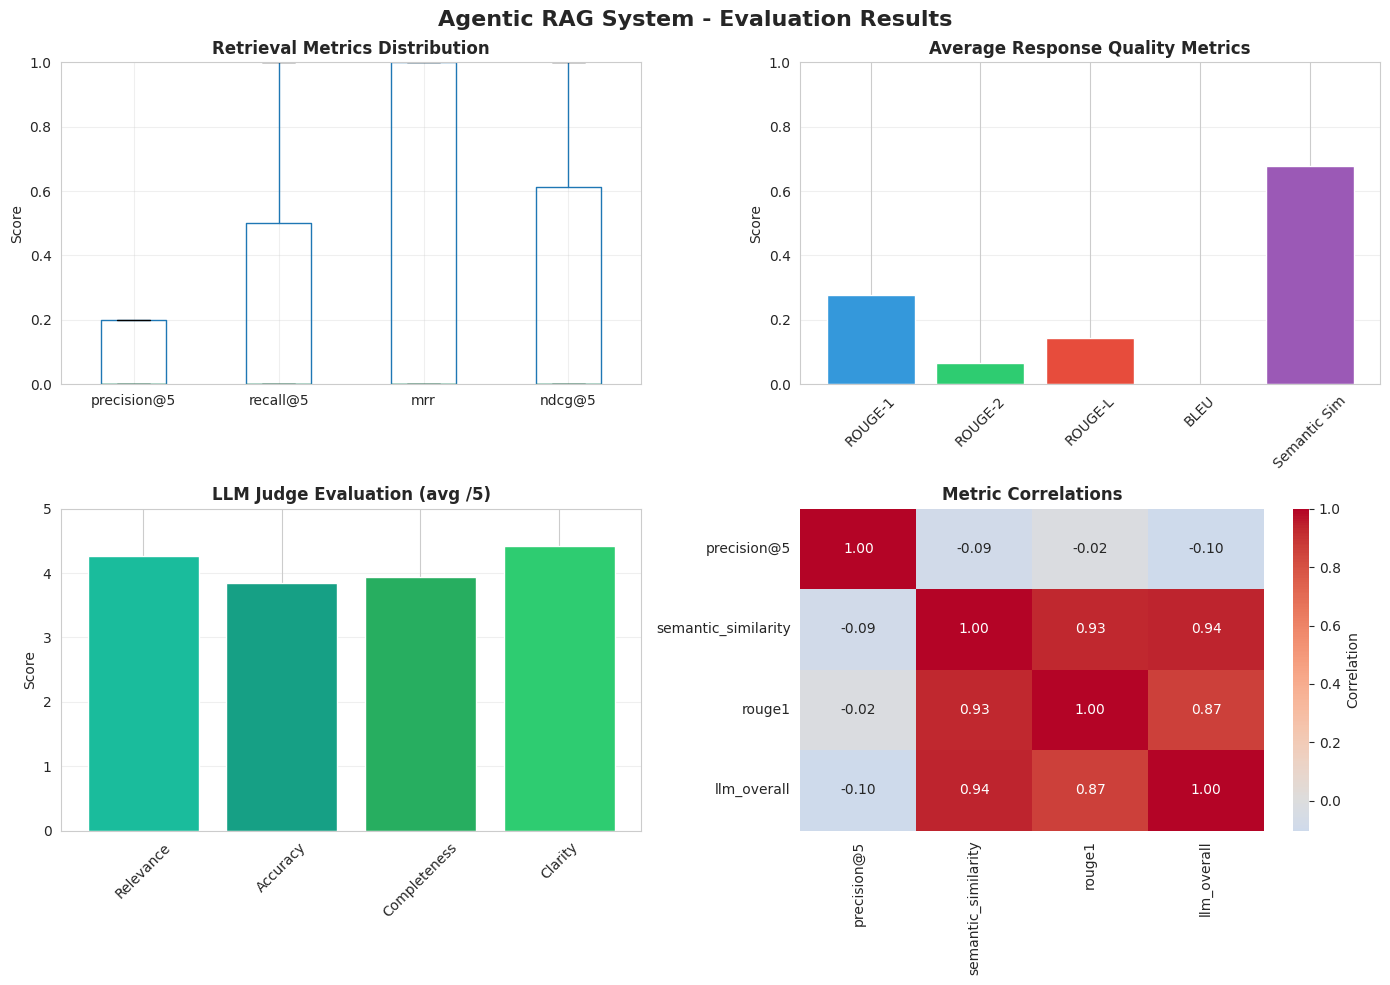

Visualization saved as: evaluation_results_visualization.png


In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 10)

# Create subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Agentic RAG System - Evaluation Results', fontsize=16, fontweight='bold')

results_df = final_results['detailed_results']

# 1. Retrieval Metrics Distribution
ax1 = axes[0, 0]
retrieval_metrics = results_df[['precision@5', 'recall@5', 'mrr', 'ndcg@5']]
retrieval_metrics.boxplot(ax=ax1)
ax1.set_title('Retrieval Metrics Distribution', fontweight='bold')
ax1.set_ylabel('Score')
ax1.set_ylim([0, 1])
ax1.grid(True, alpha=0.3)

# 2. Response Quality Metrics
ax2 = axes[0, 1]
quality_data = {
    'ROUGE-1': results_df['rouge1'].mean(),
    'ROUGE-2': results_df['rouge2'].mean(),
    'ROUGE-L': results_df['rougeL'].mean(),
    'BLEU': results_df['bleu'].mean(),
    'Semantic Sim': results_df['semantic_similarity'].mean()
}
ax2.bar(quality_data.keys(), quality_data.values(), color=['#3498db', '#2ecc71', '#e74c3c', '#f39c12', '#9b59b6'])
ax2.set_title('Average Response Quality Metrics', fontweight='bold')
ax2.set_ylabel('Score')
ax2.set_ylim([0, 1])
ax2.tick_params(axis='x', rotation=45)
ax2.grid(True, alpha=0.3, axis='y')

# 3. LLM Judge Scores
ax3 = axes[1, 0]
llm_judge_data = {
    'Relevance': results_df['llm_relevance'].mean(),
    'Accuracy': results_df['llm_accuracy'].mean(),
    'Completeness': results_df['llm_completeness'].mean(),
    'Clarity': results_df['llm_clarity'].mean()
}
ax3.bar(llm_judge_data.keys(), llm_judge_data.values(), color=['#1abc9c', '#16a085', '#27ae60', '#2ecc71'])
ax3.set_title('LLM Judge Evaluation (avg /5)', fontweight='bold')
ax3.set_ylabel('Score')
ax3.set_ylim([0, 5])
ax3.tick_params(axis='x', rotation=45)
ax3.grid(True, alpha=0.3, axis='y')

# 4. Correlation Heatmap
ax4 = axes[1, 1]
correlation_metrics = results_df[[
    'precision@5', 'semantic_similarity', 'rouge1', 'llm_overall'
]].corr()
sns.heatmap(correlation_metrics, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=ax4, cbar_kws={'label': 'Correlation'})
ax4.set_title('Metric Correlations', fontweight='bold')

plt.tight_layout()
plt.savefig('evaluation_results_visualization.png', dpi=300, bbox_inches='tight')
plt.show()

print("Visualization saved as: evaluation_results_visualization.png")

## 3.5 Statistical Analysis

In [35]:
print("\n" + "="*80)
print("STATISTICAL ANALYSIS")
print("="*80)

results_df = final_results['detailed_results']

# Key metrics for analysis
key_metrics = ['precision@5', 'recall@5', 'semantic_similarity', 'llm_overall']

print("\nDescriptive Statistics:\n")
print(results_df[key_metrics].describe())

print("\n" + "-"*80)
print("Performance Categories:\n")

# Categorize performance
def categorize_performance(row):
    avg_score = (row['precision@5'] + row['semantic_similarity'] + row['llm_overall']/5) / 3
    if avg_score >= 0.8:
        return 'Excellent'
    elif avg_score >= 0.6:
        return 'Good'
    elif avg_score >= 0.4:
        return 'Fair'
    else:
        return 'Poor'

results_df['performance_category'] = results_df.apply(categorize_performance, axis=1)

performance_counts = results_df['performance_category'].value_counts()
for category, count in performance_counts.items():
    percentage = (count / len(results_df)) * 100
    print(f"  {category:.<20} {count:>3} queries ({percentage:>5.1f}%)")

print("\n" + "-"*80)
print("Top 5 Best Performing Queries:\n")
top_queries = results_df.nlargest(5, 'llm_overall')[['query', 'llm_overall', 'semantic_similarity']]
for idx, row in top_queries.iterrows():
    print(f"  Query: {row['query'][:60]}...")
    print(f"  LLM Score: {row['llm_overall']:.2f}/5, Semantic Sim: {row['semantic_similarity']:.3f}\n")

print("\n" + "-"*80)
print("Bottom 5 Queries (Areas for Improvement):\n")
bottom_queries = results_df.nsmallest(5, 'llm_overall')[['query', 'llm_overall', 'semantic_similarity']]
for idx, row in bottom_queries.iterrows():
    print(f"  Query: {row['query'][:60]}...")
    print(f"  LLM Score: {row['llm_overall']:.2f}/5, Semantic Sim: {row['semantic_similarity']:.3f}\n")


STATISTICAL ANALYSIS

Descriptive Statistics:

       precision@5   recall@5  semantic_similarity  llm_overall
count    50.000000  50.000000            50.000000    50.000000
mean      0.092000   0.310000             0.676344     4.115000
std       0.100691   0.376477             0.239380     1.248683
min       0.000000   0.000000             0.035301     1.000000
25%       0.000000   0.000000             0.675644     4.062500
50%       0.000000   0.000000             0.763428     4.500000
75%       0.200000   0.500000             0.802768     5.000000
max       0.200000   1.000000             0.914778     5.000000

--------------------------------------------------------------------------------
Performance Categories:

  Fair................  23 queries ( 46.0%)
  Good................  21 queries ( 42.0%)
  Poor................   6 queries ( 12.0%)

--------------------------------------------------------------------------------
Top 5 Best Performing Queries:

  Query: Compare the sc

## 3.6 Export Results for Report

In [36]:
# Create summary report
summary_report = {
    'evaluation_date': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
    'system_configuration': CONFIG,
    'test_set_size': len(results_df),
    'aggregate_metrics': final_results['aggregate_metrics'],
    'performance_distribution': performance_counts.to_dict()
}

# Save as JSON
with open('evaluation_summary.json', 'w') as f:
    json.dump(summary_report, f, indent=2)

print("Evaluation summary saved to: evaluation_summary.json")

# Save detailed results
results_df.to_excel('evaluation_detailed_results.xlsx', index=False, engine='openpyxl')
print("Detailed results saved to: evaluation_detailed_results.xlsx")

print("\n" + "="*80)
print("EVALUATION COMPLETE")
print("="*80)
print("\nAll evaluation results have been saved:")
print("  1. evaluation_summary.json - Aggregate metrics and configuration")
print("  2. evaluation_detailed_results.csv - Full query-level results")
print("  3. evaluation_detailed_results.xlsx - Excel format for analysis")
print("  4. evaluation_results_visualization.png - Visual summary")
print("\nThese files are ready for inclusion in the final report.")

Evaluation summary saved to: evaluation_summary.json
Detailed results saved to: evaluation_detailed_results.xlsx

EVALUATION COMPLETE

All evaluation results have been saved:
  1. evaluation_summary.json - Aggregate metrics and configuration
  2. evaluation_detailed_results.csv - Full query-level results
  3. evaluation_detailed_results.xlsx - Excel format for analysis
  4. evaluation_results_visualization.png - Visual summary

These files are ready for inclusion in the final report.
